<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 50px;">Projeto 1 - LabIACD</div>
<div style="text-align: center; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 26px;">Notebook 2 de 3: CNN multi-escala + pyradiomics</div>

Este notebook testa se uma **rede neuronal convolucional (CNN)** consegue aprender, diretamente das imagens, features mais úteis para prever a malignidade do que as do pyradiomics, que são definidas à partida.

A CNN recebe os três cortes centrais de cada cubo (axial, coronal e sagital) em três escalas (recortes de 16, 32 e 48 mm), para ver tanto o detalhe dos nódulos pequenos como o contexto dos grandes. Depois do treino, os 192 valores da sua penúltima camada são usados como features num **Random Forest** (escolhido por tipicamente é um modelo que gera bons resultados em diversos problemas e seria computacionalmente caro testar vários modelos como foi feito no notebook1), sozinhos ou juntos com as do pyradiomics. Para que o Random Forest nunca aprenda com features de nódulos que a CNN já viu, o treino é feito em **modo cruzado**: a CNN treinada numa metade dos pacientes extrai as features da outra metade, onde se treina o Random Forest. A nota final é obtida a partir da nota esperada, com cortes aprendidos só nos nódulos do LNDb.

O notebook está organizado da seguinte forma:
- **7.1 e 7.2:** as entradas, a arquitetura da rede e o Random Forest com cortes ótimos.
- **7.3:** quatro experiências: o argmax contra os cortes ótimos, a CNN sozinha e a CNN junta com o pyradiomics.
- **7.4 a 7.6:** os modelos finais, a importância das features, a comparação das configurações face ao pyradiomics e a análise dos erros.

Antes de correr este notebook, é preciso correr as secções 2 a 4 do notebook 1, que criam os ficheiros em `data/`.

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">Configuração</div>
<br>

Importações e configuração em `configuracao.py`; o pré-processamento, o holdout, os folds, a validação cruzada e a gravação dos resultados (secção 5 do notebook 1) em `comum.py`. São os mesmos nos três notebooks, por isso os resultados são diretamente comparáveis.

In [1]:
# Importações e threads (configuracao.py, tem de vir primeiro) e ferramentas partilhadas (comum.py):
# lê data/dataset_final_esfera.csv, separa o holdout, cria os folds e define a validação e a gravação dos resultados.
# Precisa que as secções 2 a 4 do notebook 1 já tenham sido corridas (uma vez).
from configuracao import *
from comum import *
import graficos as G

c:\Users\Guilherme\.conda\envs\radiomica\Lib\site-packages\pylidc\__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr


Desenvolvimento: 2893 nódulos | holdout (LNDb): 72


<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">7. Features de uma CNN multi-escala + pyradiomics, com Random Forest</div>
<br>

Uma CNN é treinada para prever a nota a partir dos 3 cortes centrais do cubo (axial, coronal, sagital) em 3 escalas (recortes de 16, 32 e 48 mm, redimensionados para 32 × 32, janela de pulmão −1000 a 400 HU). Depois do treino, os **192 valores da penúltima camada** (64 por escala) são as features da CNN, usadas por um Random Forest (300 árvores, sem pesos), sozinhas ou juntas com as do pyradiomics (reduzidas por PCA a 16 componentes).

**Sem fuga de informação:** a CNN é treinada só com o treino de cada fold, em **modo cruzado** (o treino é dividido em 2 metades por paciente; a CNN de uma metade extrai as features da outra, onde se treina o RF; a previsão é a média dos 2 pares). As features ficam em cache em `data/cache_cnn_features/`.

**Cortes ótimos:** o RF dá a nota esperada Σ p(nota) × nota, e 4 cortes (que maximizam QWK + balanced accuracy, aprendidos só com os nódulos do LNDb do treino e com scores de um CV interno por paciente) convertem-na numa nota.

Cada nódulo tem uma chave de imagem: desenvolvimento = índice em `df`; holdout e teste com os deslocamentos da 5.5.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">7.1 Entradas e rede</div>

**Estrutura da CNN**

Cada escala (recortes de 16, 32 e 48 mm, com 3 vistas × 32 × 32) passa pela sua própria coluna convolucional. As três colunas têm a mesma estrutura, mas não partilham pesos:

| Camada | Operação | Saída |
|---|---|---|
| 1 | Convolução 3 × 3 (16 filtros) + BatchNorm + ReLU, max pooling 2 × 2 | 16 × 16 × 16 |
| 2 | Convolução 3 × 3 (32 filtros) + BatchNorm + ReLU, max pooling 2 × 2 | 32 × 8 × 8 |
| 3 | Convolução 3 × 3 (64 filtros) + BatchNorm + ReLU | 64 × 8 × 8 |
| 4 | Convolução 3 × 3 (64 filtros) + BatchNorm + ReLU | 64 × 8 × 8 |
| — | Média global de cada mapa | 64 |

As **convoluções** procuram padrões locais, desde bordas nas primeiras camadas até à forma e à margem do nódulo nas últimas. A **BatchNorm** estabiliza o treino, a **ReLU** é a função de ativação, que permite aprender relações não lineares, e o **max pooling** reduz a imagem para metade. A **média global** resume cada mapa num valor, por isso cada coluna dá 64 valores e as três juntas dão **192 features**. No treino, uma cabeça com dropout de 50% e uma camada linear com 5 saídas (softmax incluído na perda) prevê a nota. Depois, só as 192 features passam ao Random Forest. A rede tem cerca de 184 mil parâmetros.

**Porquê assim**:
A estrutura da rede foi pensada para os poucos dados disponíveis. Cada CNN é treinada com cerca de 1100 nódulos, por isso, a rede é pequena e usa cortes 2D, que dão boa parte da informação do volume com muito menos custo do que uma rede 3D. Como os nódulos vão de cerca de 3 a mais de 30 mm, cada escala tem a sua própria coluna, para aprender os filtros adequados ao detalhe que vê. A quarta camada, sem pooling, aumenta a capacidade da rede sem reduzir ainda mais a imagem de 8 × 8, e faz com que cada valor final abranja o nódulo inteiro. A média global e o dropout evitam uma camada densa com muitos parâmetros e reduzem o sobreajuste. Testámos também uma versão com cinco camadas e outras versões 3D, mas o custo computacional era muito maior e a melhoria nos resultados não o justificava, por isso ficámos com quatro e 2D.

In [2]:
# =============================================================================================
# 7.1 CNN: ENTRADAS (3 cortes × 3 escalas) E REDE
# =============================================================================================
# GPU da Apple (MPS); pôr False se o kernel morrer durante o treino das CNNs
USAR_GPU = False
ESCALAS, LADO_CNN = (16, 32, 48), 32 # recortes de 16, 32 e 48 mm -> 32 × 32
DEVICE = ("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu") if USAR_GPU else "cpu"
ARQUITETURA = "4camadas_16-32-64-64" # identifica a rede nas caches


def entradas_cnn(cubos, lote=256):
    """(n, 48, 48, 48) em HU → (n, escalas, 3 vistas, 32, 32) em [0, 1] (float16)."""
    n_threads = torch.get_num_threads()
    torch.set_num_threads(1) # uma thread: evita o conflito do OpenMP no Mac (é rápido na mesma)
    try:
        partes = []
        for ini in range(0, len(cubos), lote): # por lotes, para não encher a memória
            # Janela de pulmão: −1000 a 400 HU -> 0 a 1
            c = (np.clip(np.asarray(cubos[ini:ini + lote], dtype=np.float32), -1000, 400) + 1000) / 1400
            # 3 cortes centrais: axial, coronal e sagital (como 3 canais de uma imagem)
            v = torch.from_numpy(np.ascontiguousarray(np.stack([c[:, :, :, 24], c[:, :, 24, :], c[:, 24, :, :]], axis=1)))
            # Cada escala: recorte central de s mm, redimensionado para 32 × 32
            r = [F.interpolate(v[:, :, 24 - s // 2:24 + s // 2, 24 - s // 2:24 + s // 2], size=LADO_CNN,
                               mode="bilinear", align_corners=False) for s in ESCALAS]
            partes.append(torch.stack(r, dim=1).numpy().astype(np.float16)) # float16: metade da memória
        return np.concatenate(partes)
    finally:
        torch.set_num_threads(n_threads) # repõe as threads para o treino das CNNs


def entradas_tabela(tabela, por_dataset):
    # Entradas pela ordem de uma tabela (cada linha vai buscar o seu cubo ao dataset certo, pelo idx)
    E = np.empty((len(tabela),) + por_dataset["LIDC"].shape[1:], dtype=np.float16)
    for nome, E_ds in por_dataset.items():
        m = (tabela["dataset"] == nome).to_numpy()
        E[m] = E_ds[tabela.loc[m, "idx"].to_numpy()]
    return E


# E_BANCO: as entradas de todos os nódulos (desenvolvimento, holdout e teste), uma vez só
por_dataset = {"LIDC": entradas_cnn(np.load("data/patches.npy", mmap_mode="r")),
               "LNDb": entradas_cnn(np.load("data/patches_lndb.npy", mmap_mode="r"))}
_cubos_t = pd.read_csv("data/teste_cubos.csv")
E_BANCO = np.concatenate([entradas_tabela(df, por_dataset), entradas_tabela(df_holdout, por_dataset),
                          entradas_cnn(np.load("data/patches_teste.npy", mmap_mode="r"))])
# POS_BANCO: chave do nódulo (5.5) -> posição em E_BANCO
POS_BANCO = pd.Series(np.arange(len(E_BANCO)), index=np.concatenate(
    [df.index, OFFSET_HOLDOUT + df_holdout.index, OFFSET_TESTE + _cubos_t["idx"].to_numpy()]))
# Paciente e "é LNDb?" de cada chave (para os folds internos e para os cortes ótimos)
GRUPO_CHAVE = pd.concat([df["patient"], df_holdout["patient"].set_axis(OFFSET_HOLDOUT + df_holdout.index)])
E_LNDB_CHAVE = pd.concat([pd.Series(e_lndb, index=df.index), pd.Series(True, index=OFFSET_HOLDOUT + df_holdout.index)])
del por_dataset, _cubos_t # liberta memória


class MCNN(nn.Module):
    """Uma coluna convolucional por escala (16-32-64 filtros) → 64 valores; features() devolve os 192."""
    def __init__(self):
        super().__init__()
        # bloco: convolução 3×3 + normalização + ReLU
        bloco = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())
        # Cada coluna: 32×32 → (pool) 16×16 → (pool) 8×8 → 2 convoluções → média global → 64 valores
        self.colunas = nn.ModuleList([nn.Sequential(bloco(3, 16), nn.MaxPool2d(2), bloco(16, 32), nn.MaxPool2d(2),
                                                    bloco(32, 64), bloco(64, 64), nn.AdaptiveAvgPool2d(1), nn.Flatten())
                                      for _ in ESCALAS])
        # Cabeça: 192 valores -> 5 notas (só usada no treino)
        self.cabeca = nn.Sequential(nn.Dropout(0.5), nn.Linear(64 * len(ESCALAS), 5))

    def features(self, x):
        # x: (n, escalas, 3, 32, 32); cada escala passa pela sua coluna e os resultados juntam-se
        return torch.cat([col(x[:, k]) for k, col in enumerate(self.colunas)], dim=1)

    def forward(self, x):
        return self.cabeca(self.features(x))


EPOCAS, LOTE, LR = 30, 64, 1e-3


def aumentar(x):
    """Inversão horizontal e rotação de 90° aleatórias por nódulo (iguais em todas as escalas e vistas)."""
    # Aumento de dados: o mesmo nódulo rodado ou invertido continua a ter a mesma nota
    inv = (torch.rand(x.shape[0], device=x.device) < 0.5).view(-1, 1, 1, 1, 1)
    x = torch.where(inv, x.flip(-1), x)
    k = torch.randint(0, 4, (x.shape[0],), device=x.device) # 0, 90, 180 ou 270 graus
    out = x.clone()
    for r in range(1, 4):
        if (k == r).any():
            out[k == r] = torch.rot90(x[k == r], r, dims=(-2, -1))
    return out


def treinar_cnn(E, y_, seed):
    """30 épocas, AdamW + cosseno, entropia cruzada com pesos por classe, aumento de dados."""
    """30 épocas, AdamW + cosseno, entropia cruzada com pesos por classe, aumento de dados."""
    if DEVICE == "cpu":
        torch.set_num_threads(1) # evita o conflito do OpenMP (PyTorch × LightGBM/CatBoost) no Mac
    torch.manual_seed(seed); np.random.seed(seed) # reprodutível
    modelo = MCNN().to(DEVICE)
    # Peso de cada classe inversamente proporcional à sua frequência (as classes raras contam mais)
    peso = torch.tensor(len(y_) / (5 * np.maximum(np.bincount(y_ - 1, minlength=5), 1)), dtype=torch.float32, device=DEVICE)
    X, Y = torch.from_numpy(E), torch.from_numpy(y_ - 1).long() # notas 1–5 -> classes 0–4
    otim = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=1e-3)
    agenda = torch.optim.lr_scheduler.CosineAnnealingLR(otim, T_max=EPOCAS) # taxa de aprendizagem desce em cosseno
    g = torch.Generator().manual_seed(seed)
    for _ in range(EPOCAS):
        modelo.train()
        ordem = torch.randperm(len(X), generator=g) # baralha os nódulos em cada época
        for ini in range(0, len(X), LOTE):
            b = ordem[ini:ini + LOTE]
            if len(b) < 2: # o BatchNorm precisa de pelo menos 2
                continue
            perda = F.cross_entropy(modelo(aumentar(X[b].to(DEVICE).float())), Y[b].to(DEVICE), weight=peso)
            otim.zero_grad(); perda.backward(); otim.step()
        agenda.step()
    return modelo


@torch.no_grad()
def extrair_features(modelo, E, lote=512):
    # Os 192 valores da penúltima camada de cada nódulo (modo de avaliação: sem dropout)
    modelo.eval()
    return np.concatenate([modelo.features(torch.from_numpy(E[i:i + lote]).to(DEVICE).float()).cpu().numpy()
                           for i in range(0, len(E), lote)])


COLUNAS_CNN = [f"cnn_{i}" for i in range(64 * len(ESCALAS))]
_CACHE_FEATS = {}


def features_cnn(chaves, y_, seed=42):
    """Treina uma CNN com os nódulos 'chaves' e devolve as 192 features de todos os nódulos (com cache)."""
    chaves, y_ = np.asarray(chaves, dtype=np.int64), np.asarray(y_).astype(int)
    # A cache é indexada pelos nódulos de treino, pelas labels e pela configuração da rede
    h = hashlib.md5(chaves.tobytes() + y_.tobytes() + repr((ESCALAS, LADO_CNN, EPOCAS, LOTE, LR, ARQUITETURA, seed)).encode()).hexdigest()[:16]
    if h not in _CACHE_FEATS:
        caminho = Path("data/cache_cnn_features") / f"features_{h}.npy"
        if not caminho.exists(): # treina só se nunca foi treinada
            caminho.parent.mkdir(parents=True, exist_ok=True)
            cnn = treinar_cnn(E_BANCO[POS_BANCO.loc[chaves].to_numpy()], y_, seed)
            np.save(caminho, extrair_features(cnn, E_BANCO).astype(np.float16))
        _CACHE_FEATS[h] = pd.DataFrame(np.load(caminho), index=POS_BANCO.index, columns=COLUNAS_CNN)
    return _CACHE_FEATS[h]

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">7.2 Random Forest com cortes ótimos (`RFComCNN`)</div>

Nesta secção, as features de cada nódulo (do pyradiomics, da CNN ou de ambas) entram num Random Forest de 300 árvores (testamos usando o random forest foi foi, em geral, o modelo com melhor e mais consistente desempenho do notebook 1, e seria computacionalmente caro testar com vários modelos como fizemos anteriormente). Quando se juntam ao pyradiomics, as 192 features da CNN podem ser reduzidas por PCA, aprendido só no treino. Em vez de escolher diretamente a nota mais provável (argmax), o modelo calcula a **nota esperada**, a soma de cada nota multiplicada pela sua probabilidade, que é depois convertida numa nota por **4 cortes ótimos**. Os cortes começam em 1,5, 2,5, 3,5 e 4,5 e são ajustados um de cada vez para maximizar a balanced accuracy + QWK. São aprendidos só com os nódulos do LNDb do treino, com previsões de uma validação cruzada interna por paciente, para que o RF não seja avaliado nos nódulos com que treinou.

Quando se usa a CNN, o treino é feito com da seguinte forma: os nódulos de treino dividem-se em duas metades por paciente, a CNN treinada numa metade extrai as features da outra, e é nessa outra metade que o RF é treinado. Assim, o RF nunca aprende com features de nódulos que a CNN já viu, que seriam artificialmente boas. A previsão final é a média dos dois pares CNN + RF. Tudo isto está na classe `RFComCNN`.

In [3]:
# =============================================================================================
# 7.2 RANDOM FOREST COM CORTES ÓTIMOS (pyradiomics e/ou features da CNN)
# =============================================================================================
_W_QWK = np.subtract.outer(np.arange(1, 6), np.arange(1, 6)) ** 2 / 16.0


def _score_cortes(yt, yp):
    """bal_acc + qwk a partir da matriz de confusão."""
    M = np.bincount((yt - 1) * 5 + (yp - 1), minlength=25).reshape(5, 5).astype(float)
    reais = M.sum(1)
    bal = (np.diag(M)[reais > 0] / reais[reais > 0]).mean()
    den = (_W_QWK * np.outer(reais, M.sum(0)) / M.sum()).sum()
    return bal + (1 - (_W_QWK * M).sum() / den if den > 0 else 0.0)


def otimizar_cortes(s, y_, passos=41, voltas=3):
    """4 cortes que maximizam bal_acc + qwk, por procura coordenada (o valor atual é sempre candidato)."""
    s, y_ = np.asarray(s, dtype=float), np.asarray(y_).astype(int)
    c = np.array([1.5, 2.5, 3.5, 4.5])
    for _ in range(voltas):
        for i in range(4):
            # Cada corte testa 41 valores entre os vizinhos; fica o que dá o melhor score
            lo = c[i - 1] if i > 0 else min(s.min(), c[0])
            hi = c[i + 1] if i < 3 else max(s.max(), c[3])
            cand = np.r_[c[i], np.linspace(lo, hi, passos)]
            c[i] = cand[int(np.argmax([_score_cortes(y_, aplicar_limiares(s, np.r_[c[:i], v, c[i + 1:]])) for v in cand]))]
    return c


novo_rf = lambda seed=42: RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=N_JOBS)
score_rf = lambda rf, X: rf.predict_proba(X) @ rf.classes_ # nota esperada


def probs_rf(rf, X):
    # Probabilidades das 5 notas (com 0 nas notas que não apareceram no treino)
    P = np.zeros((len(X), 5))
    P[:, rf.classes_ - 1] = rf.predict_proba(X)
    return P


def scores_internos(X, y_, g, seed=42):
    """Scores out-of-fold dentro do treino (CV interno de 3 partes por paciente), para aprender os cortes."""
    s = np.full(len(X), np.nan)
    for a, b in StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed).split(X, y_, groups=g):
        s[b] = score_rf(novo_rf(seed).fit(X.iloc[a], y_[a]), X.iloc[b])
    return s


class RFComCNN(BaseEstimator):
    """RF com features do pyradiomics e/ou da CNN; previsao = "cortes" (cortes ótimos) ou "classe" (argmax)."""
    def __init__(self, radiomicas=True, cnn=False, n_pca=None, previsao="cortes", seed=42):
        self.radiomicas, self.cnn, self.n_pca, self.previsao, self.seed = radiomicas, cnn, n_pca, previsao, seed

    def _matriz(self, par, X, ajustar=False):
        # Matriz de entrada do RF: features do pyradiomics e/ou da CNN (opcionalmente reduzidas por PCA)
        blocos = [X] if self.radiomicas else []
        if self.cnn:
            F_ = par["feats"].loc[X.index].to_numpy(dtype=np.float32) # as 192 features de cada nódulo
            colunas = COLUNAS_CNN
            if self.n_pca:
                if ajustar: # PCA aprendido só no treino
                    par["escala"] = StandardScaler().fit(F_)
                    par["pca"] = PCA(n_components=self.n_pca, random_state=0).fit(par["escala"].transform(F_))
                F_ = par["pca"].transform(par["escala"].transform(F_))
                colunas = [f"cnn_pca{i}" for i in range(self.n_pca)]
            blocos.append(pd.DataFrame(F_, index=X.index, columns=colunas))
        return pd.concat(blocos, axis=1)

    def fit(self, X, y):
        y, chaves = np.asarray(y).astype(int), X.index.to_numpy() # o índice de X são as chaves das imagens
        if self.cnn: # modo cruzado: CNN numa metade, RF na outra
            partes = list(StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=self.seed)
                          .split(chaves, y, groups=GRUPO_CHAVE.loc[chaves].to_numpy()))
        else:
            partes = [(np.arange(len(chaves)),) * 2] # sem CNN: um só RF com todo o treino
        self.pares_, s_int, i_int = [], [], []
        for k, (p_cnn, p_rf) in enumerate(partes):
            # Para cada par: a CNN treina em p_cnn e extrai as features de p_rf, onde se treina o RF
            par = {"feats": features_cnn(chaves[p_cnn], y[p_cnn], seed=self.seed + k)} if self.cnn else {}
            Xr = self._matriz(par, X.iloc[p_rf], ajustar=True)
            par["rf"] = novo_rf(self.seed).fit(Xr, y[p_rf])
            if self.previsao == "cortes":
                s_int.append(scores_internos(Xr, y[p_rf], GRUPO_CHAVE.loc[chaves[p_rf]].to_numpy(), self.seed))
                i_int.append(p_rf)
            self.pares_.append(par)
        if self.previsao == "cortes": # cortes só com o LNDb (se ≥ 40 nódulos)
            i, s = np.concatenate(i_int), np.concatenate(s_int)
            sel = E_LNDB_CHAVE.loc[chaves[i]].to_numpy()
            sel = sel if sel.sum() >= 40 else np.ones(len(i), dtype=bool)
            self.cortes_ = otimizar_cortes(s[sel], y[i][sel])
        return self

    def predict(self, X):
        # Média dos pares (modo cruzado) -> argmax das probabilidades, ou nota esperada + cortes
        if self.previsao == "classe":
            return np.mean([probs_rf(p["rf"], self._matriz(p, X)) for p in self.pares_], axis=0).argmax(1) + 1
        return aplicar_limiares(np.mean([score_rf(p["rf"], self._matriz(p, X)) for p in self.pares_], axis=0), self.cortes_)

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">7.3 Experiências: argmax vs. cortes, CNN sozinha, CNN + pyradiomics</div>

Esta secção testa quatro configurações do Random Forest, todas avaliadas com a validação cruzada do notebook 1 (3 seeds × 5 folds, pacientes separados) e com as métricas calculadas no LNDb. As duas primeiras usam só o pyradiomics e diferem apenas na forma de chegar à nota: pelo **argmax** das probabilidades ou pela nota esperada com **cortes ótimos**. A comparação entre elas mede o efeito dos cortes. A terceira usa **só as features da CNN**, para ver se a rede aprende, por si só, algo útil sobre a malignidade. A quarta junta ao pyradiomics as **16 componentes principais da CNN**, para ver se a rede acrescenta informação que o pyradiomics não tem.

Para que uma configuração seja considerada melhor, tem de superar a outra em pelo menos 3 das 4 métricas. O treino das CNNs é a parte mais demorada: com 2 metades em cada um dos 15 folds, são treinadas 30 redes. Por isso, as features ficam em cache, e as duas configurações com a CNN usam as mesmas redes.

In [14]:
%%capture saida_73
# 7.3 Experiências: argmax vs. cortes ótimos; CNN sozinha; CNN + pyradiomics (resultados em cache)
CFG_CNN = repr((ESCALAS, LADO_CNN, EPOCAS, LOTE, LR, ARQUITETURA)) # entra na chave da cache 
_, oof_rad_classe = avaliar(lambda s: RFComCNN(previsao="classe"), chave=("RFComCNN", "pyradiomics", "classe"))
_, oof_rad = avaliar(lambda s: RFComCNN(), chave=("RFComCNN", "pyradiomics", "cortes"))
_, oof_cnn = avaliar(lambda s: RFComCNN(radiomicas=False, cnn=True), # treina 30 CNNs (em cache)
                     chave=("RFComCNN", "cnn", "cortes", CFG_CNN))
_, oof_cnn_rad = avaliar(lambda s: RFComCNN(cnn=True, n_pca=16), # as mesmas CNNs
                         chave=("RFComCNN", "cnn+pyradiomics", 16, "cortes", CFG_CNN))
t = tabela({"pyradiomics (argmax)": oof_rad_classe, "pyradiomics (cortes ótimos)": oof_rad,
            "CNN (cortes ótimos)": oof_cnn, "CNN + pyradiomics (cortes ótimos)": oof_cnn_rad}, recall=True)

print("Cortes melhores do que o argmax:", melhor_em_s(oof_rad, oof_rad_classe))
print("CNN + pyradiomics melhor do que o pyradiomics:", melhor_em_s(oof_cnn_rad, oof_rad))
print("CNN melhor do que o pyradiomics:", melhor_em_s(oof_cnn, oof_rad))

In [15]:
print(saida_73.stdout)          # os prints ("Cortes melhores do que o argmax: ...")
for o in saida_73.outputs:      # as tabelas e os gráficos
    display(o)

Cortes melhores do que o argmax: True
CNN + pyradiomics melhor do que o pyradiomics: False
CNN melhor do que o pyradiomics: False



,bal_acc,macro_f1,qwk,mae,S
pyradiomics (cortes ótimos),0.487,0.407,0.550,0.634,0.810
CNN + pyradiomics (cortes ótimos),0.467,0.401,0.539,0.639,0.768
CNN (cortes ótimos),0.463,0.393,0.534,0.647,0.743
pyradiomics (argmax),0.452,0.417,0.507,0.697,0.678


,classe 1,classe 2,classe 3,classe 4,classe 5
pyradiomics (cortes ótimos),0.42,0.72,0.36,0.02,0.92
CNN + pyradiomics (cortes ótimos),0.39,0.75,0.29,0.03,0.88
CNN (cortes ótimos),0.46,0.69,0.29,0.00,0.88
pyradiomics (argmax),0.48,0.43,0.61,0.08,0.67


> **Cortes ótimos vs. argmax:** os cortes melhoram a balanced accuracy (0,452 → 0,487), o QWK (0,507 → 0,550) e o MAE (0,697 → 0,634), e só o macro F1 desce ligeiramente (0,417 → 0,407). Como superam o argmax em três das quatro métricas, os cortes são considerados melhores, e o S passa de 0,678 para 0,810. O que muda é sobretudo a nota prevista: com o argmax, o modelo prevê muitas vezes a nota 3, a mais frequente no LIDC (recall de 0,61 na nota 3 e de 0,43 na nota 2); com os cortes, aprendidos só no LNDb, onde a nota 2 é muito mais comum, passa a prever sobretudo a nota 2 (recall de 0,72 na nota 2 e de 0,36 na nota 3).

> **CNN sozinha:** fica abaixo do pyradiomics com cortes nas quatro métricas (balanced accuracy 0,463 contra 0,487, macro F1 0,393 contra 0,407, QWK 0,534 contra 0,550 e MAE 0,647 contra 0,634), com um S de 0,743 contra 0,810. As diferenças são pequenas, o que mostra que a rede aprende, por si só, informação útil das imagens, quase tanta como as features do pyradiomics, mas não chega para as superar.

> **CNN + pyradiomics:** também não supera o pyradiomics sozinho (S de 0,768 contra 0,810), ficando ligeiramente abaixo nas quatro métricas, embora à frente da CNN sozinha. Juntar as 16 componentes da CNN ao pyradiomics não acrescenta informação nova: o que a CNN capta parece já estar, em grande parte, nas features do pyradiomics.

> **Em todas as configurações com cortes**, a nota 4 quase nunca é acertada (recall entre 0,00 e 0,03) e a nota 3 continua difícil (0,29 a 0,36), enquanto a nota 5 é bem reconhecida (0,88 a 0,92). Os erros concentram-se nas notas intermédias.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">7.4 Modelos finais e importância das features</div>

As três configurações com cortes ótimos (pyradiomics, CNN e CNN + pyradiomics) são agora treinadas com todo o conjunto de desenvolvimento e usadas para prever o holdout. Os resultados ficam guardados em `resultados/`, juntamente com as previsões out-of-fold da 7.3, para serem comparados na 7.5. Se um modelo já tiver sido guardado com os mesmos dados e a mesma configuração, é reutilizado em vez de ser treinado de novo.

Para perceber se o Random Forest usa de facto a informação da CNN, mostra-se também a importância das features no modelo CNN + pyradiomics. A importância de cada feature mede quanto ela ajuda as árvores a separar as notas (redução de impureza) e é a média dos dois pares CNN + RF do modo cruzado. A soma da importância das 16 componentes da CNN indica quanto peso o modelo dá à rede face ao pyradiomics.

In [ ]:
%%capture saida_cnn
print("\n".join(l for l in saida_cnn.stdout.splitlines() if "holdout:" in l or "Importância" in l))
for o in saida_cnn.outputs:
    display(o)

# 7.4 Modelos finais das três configurações (holdout) e importância das features
CONFIGS_12 = {"pyradiomics (RF, cortes)": (dict(), oof_rad),
              "CNN (RF, cortes)": (dict(radiomicas=False, cnn=True), oof_cnn),
              "CNN + pyradiomics (RF, cortes)": (dict(cnn=True, n_pca=16), oof_cnn_rad)}
modelos_12 = {nome: finalizar_modelo(nome, lambda pop, c=c: RFComCNN(**c), oof, chaves=True,
                                     descricao=f"RFComCNN {c} {CFG_CNN}", teste=False)
              for nome, (c, oof) in CONFIGS_12.items()}

# Importância das features no modelo CNN + pyradiomics
X_dev_prep = aplicar_preprocessamento(ajustar_preprocessamento(X_dev, y), X_dev)
m = modelos_12["CNN + pyradiomics (RF, cortes)"] or RFComCNN(cnn=True, n_pca=16).fit(X_dev_prep, y)
imp = pd.Series(np.mean([p["rf"].feature_importances_ for p in m.pares_], axis=0),
                index=m._matriz(m.pares_[0], X_dev_prep.iloc[:1]).columns)
print(f"Importância das features da CNN: {imp[imp.index.str.startswith('cnn_')].sum():.1%}")
G.grafico_importancias(imp, 15, "As 15 features mais importantes (a escuro, as da CNN)", destacar="cnn_")

pyradiomics (RF, cortes) | holdout: bal_acc 0.359 | macro_f1 0.294 | qwk 0.402 | mae 0.750
CNN (RF, cortes) | holdout: bal_acc 0.335 | macro_f1 0.289 | qwk 0.370 | mae 0.736
CNN + pyradiomics (RF, cortes) | holdout: bal_acc 0.351 | macro_f1 0.331 | qwk 0.421 | mae 0.764
Importância das features da CNN: 7.6%


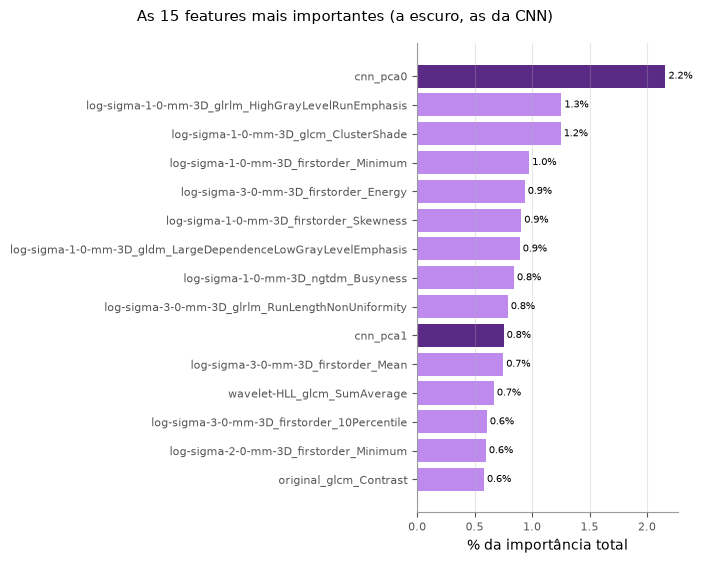

In [13]:
print("\n".join(l for l in saida_cnn.stdout.splitlines() if "holdout:" in l or "Importância" in l))
for o in saida_cnn.outputs:
    display(o)

> **Holdout:** os resultados ficam muito próximos e não há uma configuração melhor em todas as métricas. O pyradiomics tem a melhor balanced accuracy (0,359), a CNN + pyradiomics o melhor macro F1 (0,331) e o melhor QWK (0,421), e a CNN sozinha o melhor MAE (0,736). Todas ficam bastante abaixo da validação cruzada (por exemplo, o QWK do pyradiomics passa de 0,550 para 0,402). Com 72 nódulos no holdout, estas diferenças são pequenas e têm de ser lidas com os intervalos de confiança da 7.5; no conjunto, o holdout não contradiz a validação cruzada (7.3), em que a CNN não supera o pyradiomics.

> **Importância das features:** as 16 componentes da CNN somam 7,6% da importância do modelo CNN + pyradiomics. É pouco no total, mas são apenas 16 entre cerca de 300 features, e a primeira componente (`cnn_pca0`) é a feature mais importante de todas (2,2%), com mais uma componente (`cnn_pca1`, 0,8%) entre as 15 primeiras. As restantes são sobretudo texturas e estatísticas de intensidade do pyradiomics nas imagens filtradas com LoG. A importância está muito dispersa (nenhuma feature passa de 2,2%): o Random Forest combina muitas features com pouco peso cada. Isto ajuda a explicar a 7.3: a CNN capta informação útil, mas o modelo já a encontra, em grande parte, espalhada pelas features do pyradiomics.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">7.5 Comparação das configurações</div>

As três configurações (pyradiomics, CNN e CNN + pyradiomics, todas com Random Forest e cortes ótimos), comparadas como na 6.9 do notebook 1: LNDb com intervalos de confiança (bootstrap por paciente) e a mesma regra de decisão, agora com o **pyradiomics (RF, cortes)** como referência (a pergunta é se a CNN acrescenta alguma coisa); 

In [7]:
# 7.5 Comparação das três configurações (comum.py): escolha pela regra dos 3 em 4 face ao pyradiomics
ESCOLHA_CNN = comparar_modelos(list(CONFIGS_12), referencia="pyradiomics (RF, cortes)", regra="3de4")

Aviso: RF_SMOTE.pkl foi guardado com outros dados, folds ou features e foi ignorado.
Superam pyradiomics (RF, cortes) em 3 de 4 métricas no LNDb: nenhum | ESCOLHIDO: pyradiomics (RF, cortes)
LNDb: valor [IC 95%] | diferença face a pyradiomics (RF, cortes) (* = o IC da diferença exclui o zero)


,bal_acc,macro_f1,qwk,mae,rank
"pyradiomics (RF, cortes)","0.487 [0.432, 0.534] | +0.000","0.407 [0.326, 0.463] | +0.000","0.550 [0.420, 0.640] | +0.000","0.634 [0.548, 0.730] | +0.000",1.0
"CNN (RF, cortes)","0.463 [0.408, 0.513] | -0.024","0.393 [0.320, 0.445] | -0.014","0.534 [0.406, 0.631] | -0.017","0.647 [0.553, 0.746] | +0.013",3.0
"CNN + pyradiomics (RF, cortes)","0.467 [0.418, 0.511] | -0.020 *","0.401 [0.318, 0.459] | -0.007","0.539 [0.400, 0.639] | -0.011","0.639 [0.557, 0.723] | +0.005",2.0


Holdout: 72 nódulos | classes: [26, 25, 14, 5, 2] | valor [IC 95%]:


,bal_acc,macro_f1,qwk,mae
"pyradiomics (RF, cortes)","0.359 [0.215, 0.498]","0.294 [0.179, 0.378]","0.402 [0.068, 0.627]","0.750 [0.534, 1.063]"
"CNN (RF, cortes)","0.335 [0.196, 0.466]","0.289 [0.168, 0.377]","0.370 [0.071, 0.562]","0.736 [0.556, 1.047]"
"CNN + pyradiomics (RF, cortes)","0.351 [0.184, 0.498]","0.331 [0.171, 0.456]","0.421 [0.106, 0.649]","0.764 [0.561, 1.048]"


> **Escolha:** nenhuma das configurações com a CNN supera o pyradiomics em três das quatro métricas no LNDb, pelo que fica o **pyradiomics (RF, cortes)**, que é também a de menor rank médio (1,0). As duas configurações com a CNN ficam ligeiramente abaixo nas quatro métricas: a CNN + pyradiomics tem diferenças de −0,020 na balanced accuracy, −0,007 no macro F1, −0,011 no QWK e +0,005 no MAE, e a CNN sozinha de −0,024, −0,014, −0,017 e +0,013.

> **Incerteza no LNDb:** as diferenças são pequenas e os intervalos de confiança das três configurações sobrepõem-se quase por completo (por exemplo, QWK de 0,42 a 0,64 no pyradiomics e de 0,41 a 0,63 na CNN). A única diferença em que o intervalo exclui o zero é a descida da balanced accuracy na CNN + pyradiomics (−0,020). No conjunto, a CNN não acrescenta informação ao pyradiomics, mas também não piora o modelo de forma clara.

> **Holdout:** com 72 nódulos (26, 25, 14, 5 e 2 por nota), os intervalos de confiança são muito largos (o QWK do pyradiomics vai de 0,07 a 0,63), e as diferenças entre as três configurações não são conclusivas: o pyradiomics tem a melhor balanced accuracy, a CNN + pyradiomics o melhor macro F1 e QWK, e a CNN o melhor MAE. Todas ficam abaixo da validação cruzada, o que confirma o otimismo das estimativas obtidas com os mesmos dados usados nas escolhas.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">7.6 Análise de Resultados </div>

Aviso: RF_SMOTE.pkl foi guardado com outros dados, folds ou features e foi ignorado.


Aviso: RF_SMOTE.pkl foi guardado com outros dados, folds ou features e foi ignorado.


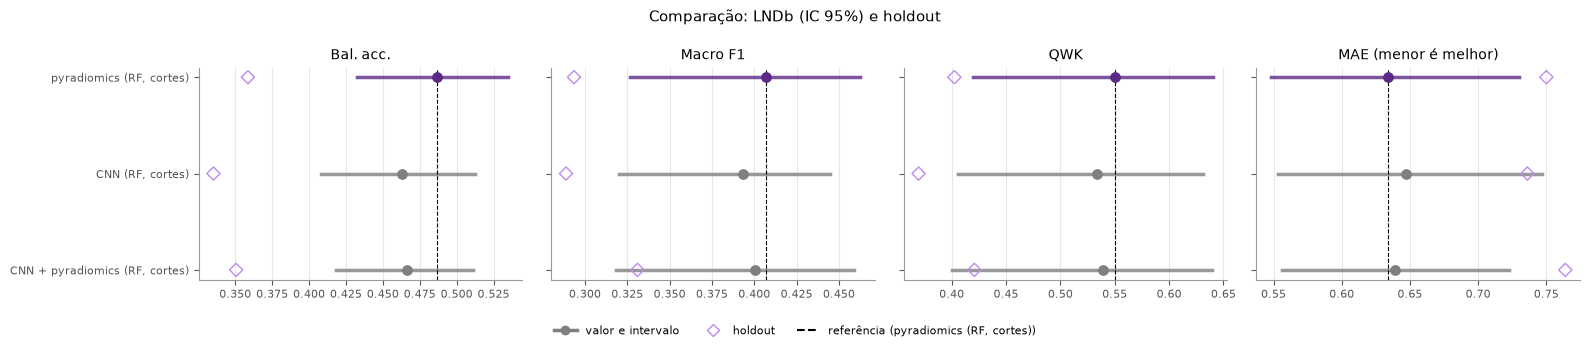

Aviso: RF_SMOTE.pkl foi guardado com outros dados, folds ou features e foi ignorado.


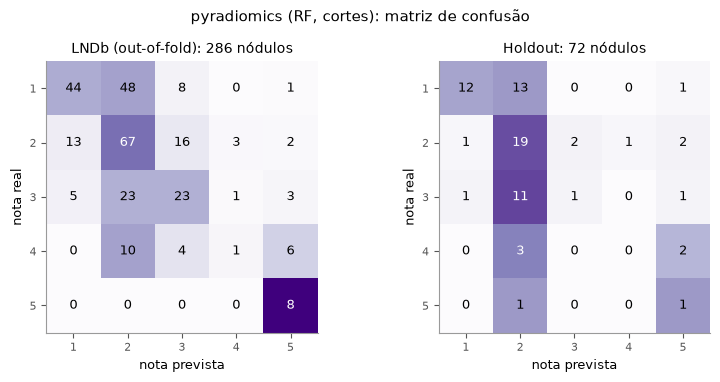

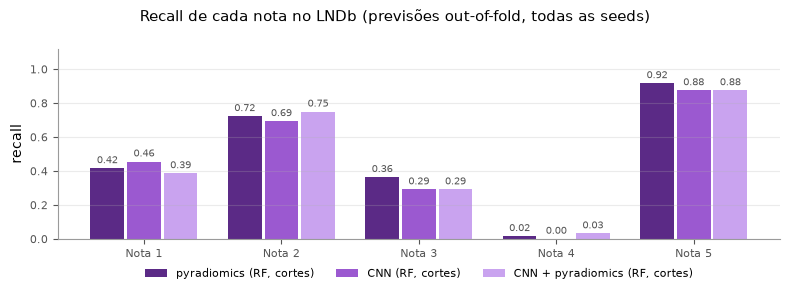

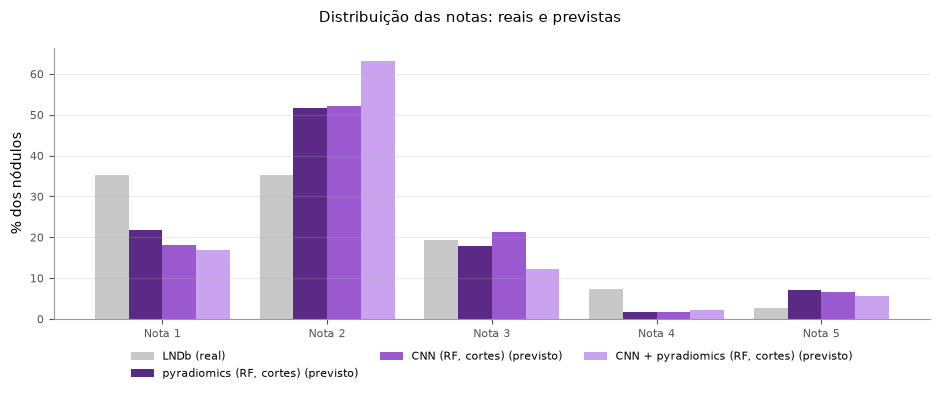

In [8]:
# 7.6 Análise dos resultados (graficos.py)
R3 = {"pyradiomics (argmax)": (None, oof_rad_classe), "pyradiomics (cortes ótimos)": (None, oof_rad),
      "CNN (cortes ótimos)": (None, oof_cnn), "CNN + pyradiomics (cortes ótimos)": (None, oof_cnn_rad)}
G.tabela_comparacao(list(CONFIGS_12), escolhido=ESCOLHA_CNN)
G.grafico_comparacao(list(CONFIGS_12), referencia="pyradiomics (RF, cortes)")
G.matrizes_confusao(ESCOLHA_CNN)
y_l = y.to_numpy()[e_lndb]
oof_l = {n: oof.to_numpy()[e_lndb] for n, (_, oof) in CONFIGS_12.items()}
G.grafico_recall({n: (np.tile(y_l, p.shape[1]), p.T.ravel()) for n, p in oof_l.items()},
                 "Recall de cada nota no LNDb (previsões out-of-fold, todas as seeds)")
G.grafico_distribuicao({"LNDb (real)": y_l, **{f"{n} (previsto)": p[:, 0] for n, p in oof_l.items()}},
                       "Distribuição das notas: reais e previstas")

> **Comparação geral:** o pyradiomics (RF, cortes) tem o maior S no LNDb (0,810, contra 0,768 da CNN + pyradiomics e 0,743 da CNN) e é o melhor nas quatro métricas. No gráfico de intervalos, porém, os intervalos das três configurações sobrepõem-se quase por completo e cruzam a linha da referência, o que confirma que as diferenças são pequenas face à incerteza. No holdout (losangos), não há uma configuração melhor em todas as métricas, e todas ficam abaixo da validação cruzada.

> **Erros do modelo escolhido:** a maioria dos erros é entre notas vizinhas, o que explica um QWK razoável apesar de uma balanced accuracy modesta. O problema principal é a nota 2, que "atrai" as notas vizinhas: é a mais bem acertada (recall de 0,72), mas muitos nódulos de nota 1 e de nota 3 são previstos como nota 2. A nota 5 é muito bem reconhecida (recall de 0,92), e a nota 4 quase nunca é acertada (0,02).

> **Recall e distribuição das notas:** as três configurações têm perfis muito parecidos. A CNN reconhece um pouco melhor a nota 1 (recall de 0,46, contra 0,42 do pyradiomics), mas pior as notas 3 e 5, e a nota 4 continua quase impossível em todas (recall ≤ 0,03). A distribuição das notas previstas mostra a causa: os três modelos preveem a nota 2 em mais de metade dos nódulos (52% no pyradiomics e na CNN, 63% na CNN + pyradiomics), contra 35% no LNDb, e preveem poucas notas 1 (17% a 22%, contra 35%) e quase nenhuma nota 4 (cerca de 2%, contra 7%). Os cortes ótimos, ao maximizarem o S, empurram as previsões para a nota 2, uma nota central que raramente fica muito longe da verdadeira. Isto favorece o QWK e o MAE, mas custa o recall das notas 1 e 4.

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">8. Conclusões (CNN)</div>
<br>

O principal resultado deste notebook é que a **CNN aprende, por si só, informação útil sobre a malignidade, mas não supera o pyradiomics**. Usadas num Random Forest com cortes ótimos, as 192 features da rede ficam perto das cerca de 1130 features do pyradiomics, mas abaixo delas nas quatro métricas no LNDb (balanced accuracy 0,463 contra 0,487, macro F1 0,393 contra 0,407, QWK 0,534 contra 0,550 e MAE 0,647 contra 0,634), com um S de 0,743 contra 0,810 (7.3). Juntar as 16 componentes principais da CNN ao pyradiomics também não melhora o modelo (S de 0,768): o que a rede capta parece já estar, em grande parte, nas features do pyradiomics. Ainda assim, no modelo combinado, a primeira componente da CNN é a feature mais importante de todas (2,2%), e as 16 componentes somam 7,6% da importância, um peso elevado para tão poucas features (7.4). Pela regra dos 3 em 4, nenhuma configuração com a CNN supera a referência, e a configuração escolhida é o **pyradiomics (RF, cortes)** (7.5).

Os **cortes ótimos** melhoram claramente o argmax: melhoram a balanced accuracy (0,452 → 0,487), o QWK (0,507 → 0,550) e o MAE (0,697 → 0,634), com o macro F1 praticamente igual, e o S passa de 0,678 para 0,810. O seu efeito principal é deslocar as previsões: com o argmax, o Random Forest prevê muitas vezes a nota 3, a mais frequente no LIDC, e com os cortes, aprendidos só no LNDb, passa a prever sobretudo a nota 2. Esta tendência mantém-se no modelo escolhido, que prevê a nota 2 em 52% dos nódulos (35% no LNDb real) e por isso reconhece mal as notas 1 e 3 (7.6). Os erros são quase todos entre notas vizinhas, o que mantém o QWK razoável, mas a nota 4 continua quase impossível de acertar (recall ≤ 0,03).

No **holdout**, não há uma configuração melhor em todas as métricas: o pyradiomics tem a melhor balanced accuracy, a CNN + pyradiomics o melhor macro F1 e QWK, e a CNN o melhor MAE. Com apenas 72 nódulos, e só 5 de nota 4 e 2 de nota 5, os intervalos de confiança são muito largos (o QWK do pyradiomics vai de 0,07 a 0,63) e sobrepõem-se entre as três configurações. Também no LNDb os intervalos se sobrepõem bastante, pelo que nenhuma das diferenças entre as três configurações é estatisticamente segura.

Estes resultados têm várias **limitações**. Cada CNN é treinada com cerca de 1100 nódulos (metade do treino de cada fold, por causa do modo cruzado), o que é pouco para uma rede neuronal e obriga a uma arquitetura pequena. A rede vê apenas três cortes 2D de cada nódulo, e não o volume 3D completo. A perda (entropia cruzada) trata as notas como classes independentes e não respeita a sua ordem, pelo que confundir as notas 1 e 5 custa o mesmo que confundir as notas 1 e 2. Por fim, por razões de custo computacional, só se testou o Random Forest com a configuração do modelo base do notebook 1 (sem os pesos de classe nem o peso do LNDb da configuração final), e não os restantes modelos nem a configuração otimizada.